In [31]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

In [33]:
data = pd.read_csv(
    r"C:\Users\Dell\OneDrive\Desktop\ir_lab\enron_spam_data.csv",
    encoding='latin-1'
)

print(data.head())
print(data.columns)

   Message ID                       Subject  \
0           0  christmas tree farm pictures   
1           1      vastar resources , inc .   
2           2  calpine daily gas nomination   
3           3                    re : issue   
4           4     meter 7268 nov allocation   

                                             Message Spam/Ham        Date  
0                                                NaN      ham  1999-12-10  
1  gary , production from the high island larger ...      ham  1999-12-13  
2             - calpine daily gas nomination 1 . doc      ham  1999-12-14  
3  fyi - see note below - already done .\nstella\...      ham  1999-12-14  
4  fyi .\n- - - - - - - - - - - - - - - - - - - -...      ham  1999-12-14  
Index(['Message ID', 'Subject', 'Message', 'Spam/Ham', 'Date'], dtype='object')


In [34]:
data = data.fillna('')

data['message'] = data['Subject'].astype(str) + ' ' + data['Message'].astype(str)

data['labels'] = data['Spam/Ham'].str.lower().map({
    'ham': 0,
    'spam': 1
})

data = data[['labels', 'message']]

print(data.head())
print(data['labels'].value_counts())

   labels                                            message
0       0                      christmas tree farm pictures 
1       0  vastar resources , inc . gary , production fro...
2       0  calpine daily gas nomination - calpine daily g...
3       0  re : issue fyi - see note below - already done...
4       0  meter 7268 nov allocation fyi .\n- - - - - - -...
labels
1    17171
0    16545
Name: count, dtype: int64


In [35]:
print("Dataset Shape:", data.shape)

print("\nFirst 5 Records:")
print(data.head())

print("\nClass Distribution:")
print(data['labels'].value_counts())

print("\nMissing Values:")
print(data.isnull().sum())

Dataset Shape: (33716, 2)

First 5 Records:
   labels                                            message
0       0                      christmas tree farm pictures 
1       0  vastar resources , inc . gary , production fro...
2       0  calpine daily gas nomination - calpine daily g...
3       0  re : issue fyi - see note below - already done...
4       0  meter 7268 nov allocation fyi .\n- - - - - - -...

Class Distribution:
labels
1    17171
0    16545
Name: count, dtype: int64

Missing Values:
labels     0
message    0
dtype: int64


In [36]:
from sklearn.model_selection import train_test_split

X = data['message']
y = data['labels']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 26972
Testing Data: 6744


In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    max_features=5000
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Training Shape:", X_train_vec.shape)
print("Testing Shape:", X_test_vec.shape)

Training Shape: (26972, 5000)
Testing Shape: (6744, 5000)


In [38]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

knn.fit(X_train_vec, y_train)

pred = knn.predict(X_test_vec)

print("Predictions:", pred)

Predictions: [1 1 1 ... 1 1 1]


In [39]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

Confusion Matrix:
[[1380 1929]
 [   3 3432]]
True Negative: 1380
False Positive: 1929
False Negative: 3
True Positive: 3432


In [40]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, pred)

precision = tp / (tp + fp) if (tp + fp) != 0 else 0

sensitivity = tp / (tp + fn) if (tp + fn) != 0 else 0

specificity = tn / (tn + fp) if (tn + fp) != 0 else 0

print("Accuracy   :", accuracy)
print("Precision  :", precision)
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Accuracy   : 0.7135231316725978
Precision  : 0.6401790710688304
Sensitivity: 0.9991266375545852
Specificity: 0.4170444242973708


In [41]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    pred,
    target_names=['Ham', 'Spam']
))

              precision    recall  f1-score   support

         Ham       1.00      0.42      0.59      3309
        Spam       0.64      1.00      0.78      3435

    accuracy                           0.71      6744
   macro avg       0.82      0.71      0.68      6744
weighted avg       0.82      0.71      0.69      6744



In [42]:
new_email = [
    "Congratulations! You won a free prize. Click now to claim your reward."
]

new_vec = vectorizer.transform(new_email)

result = knn.predict(new_vec)

print("New Email:", new_email[0])

if result[0] == 1:
    print("Classification: Spam")
else:
    print("Classification: Not Spam (Ham)")

New Email: Congratulations! You won a free prize. Click now to claim your reward.
Classification: Spam


In [43]:
emails = [
    "Congratulations! You won a free lottery prize.",
    "Please find attached the meeting schedule for tomorrow.",
    "Claim your free cash reward now.",
    "Can we schedule a meeting for Monday?"
]

email_vec = vectorizer.transform(emails)

predictions = knn.predict(email_vec)

for email, result in zip(emails, predictions):
    print("\nEmail:", email)
    print("Prediction:", "Spam" if result == 1 else "Ham")


Email: Congratulations! You won a free lottery prize.
Prediction: Spam

Email: Please find attached the meeting schedule for tomorrow.
Prediction: Spam

Email: Claim your free cash reward now.
Prediction: Spam

Email: Can we schedule a meeting for Monday?
Prediction: Spam


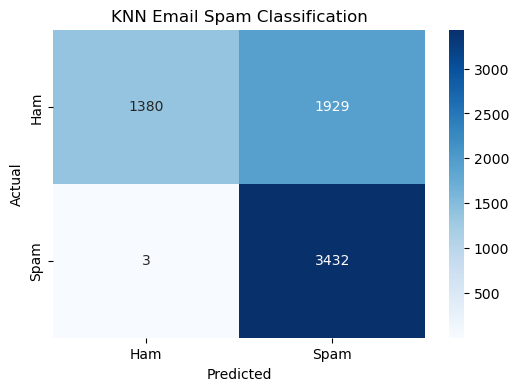

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Email Spam Classification")

plt.show()